In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

El acta de constitución de un proyecto de obra civil fija, junto al plazo y al presupuesto, un **indicador de sostenibilidad: emisiones del proyecto ≤ 470 t CO₂**. El cuadro de prelaciones, las duraciones (semanas) y las emisiones planificadas de cada actividad (t CO₂, repartidas uniformemente en su duración) se adjuntan.

In [4]:
#| tbl-cap: "Planificación del proyecto y presupuesto de emisiones"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, emisiones_plan
    ('A'     , '---'      , 6       , 30            ),
    ('B'     , '---'      , 5       , 30            ),
    ('C'     , 'B'        , 3       , 70            ),
    ('D'     , 'A,B'      , 6       , 80            ),
    ('E'     , 'C'        , 5       , 50            ),
    ('F'     , 'D,E'      , 7       , 20            ),
    ('G'     , 'F'        , 1       , 80            ),
    ('H'     , 'E'        , 6       , 40            ),
    ('I'     , 'G,H'      , 1       , 70            ),
], columns=['activity', 'predecessor', 'duration', 'emisiones_plan']).set_index('activity')
datos_enunciado

,predecessor,duration,emisiones_plan
activity,,,
A,---,6,30
B,---,5,30
C,B,3,70
D,"A,B",6,80
E,C,5,50
F,"D,E",7,20
G,F,1,80
H,E,6,40
I,"G,H",1,70


Al final de la semana 11 se dispone del avance físico verificado de cada actividad (`performed`, %) y de las emisiones reales acumuladas de cada una, calculadas a partir de los partes de combustible, las facturas de electricidad y los albaranes (`emisiones_reales`, t CO₂).

In [5]:
#| tbl-cap: "Seguimiento al final de la semana 11"
#| label: tbl-seguimiento
seguimiento = pd.DataFrame([
#  activity, actual_duration, performed, emisiones_reales
    ('A'     , 6              , 100      , 42              ),
    ('B'     , 5              , 100      , 36              ),
    ('C'     , 3              , 100      , 84              ),
    ('D'     , 5              , 33       , 31.7            ),
    ('E'     , 3              , 30       , 19.5            ),
    ('F'     , 0              , 0        , 0               ),
    ('G'     , 0              , 0        , 0               ),
    ('H'     , 0              , 0        , 0               ),
    ('I'     , 0              , 0        , 0               ),
], columns=['activity', 'actual_duration', 'performed', 'emisiones_reales']).set_index('activity')
seguimiento

,actual_duration,performed,emisiones_reales
activity,,,
A,6,100,42.0
B,5,100,36.0
C,3,100,84.0
D,5,33,31.7
E,3,30,19.5
F,0,0,0.0
G,0,0,0.0
H,0,0,0.0
I,0,0,0.0


> **De: Jefe de proyecto (borrador del informe al patrocinador)**
> Emisiones acumuladas a la semana 11: 213 t, por debajo de las 227 t previstas a esta fecha en el plan. El indicador de sostenibilidad va bien; no hace falta más detalle.

Las fuentes de emisión del proyecto, para el inventario, son las siguientes: gasóleo de la maquinaria propia; grupo electrógeno de la obra; electricidad comprada a la red; transporte de materiales por un transportista contratado; vehículos de la subcontrata de montaje.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S5 — Metas de sostenibilidad en los documentos formales.** Si el acta de constitución, el caso de negocio o el contrato fijan un indicador de sostenibilidad (toneladas, kWh, residuos valorizados), se planifica, se mide y se informa como el plazo y el coste: contra lo planificado a la fecha y con previsión al cierre. Informar sólo el acumulado, sin la referencia, es dar un dato cierto que lleva a una conclusión equivocada (C2 y C3 de la lección 19). *(cf. PMBOK 8 §3.7.1 (KPI de sostenibilidad en el acta de constitución y el caso de negocio).)*
- **S6 — Alcances de las emisiones.** Las emisiones de un proyecto se clasifican por quién controla la fuente: alcance 1, combustión en fuentes propias o controladas (maquinaria y vehículos propios, generadores); alcance 2, electricidad comprada; alcance 3, el resto de la cadena (subcontratas, transporte ajeno, materiales comprados, viajes). A qué alcance pertenece cada fuente tiene respuesta determinada, y el alcance 3 no deja de contar por ser ajeno. *(cf. GHG Protocol, estándar corporativo; UNE-EN ISO 14064-1; registro de huella de carbono del MITECO (RD 163/2014).)*
- **Norma o dato de referencia — alcance 1: emisiones directas de fuentes propias o controladas (combustible de maquinaria y vehículos propios, generadores en obra); alcance 2: emisiones indirectas de la electricidad comprada; alcance 3: las demás emisiones indirectas de la cadena de valor (materiales comprados, transporte contratado, subcontratas, residuos, viajes)** *(GHG Protocol, Corporate Accounting and Reporting Standard; UNE-EN ISO 14064-1.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [6]:
pregunta_1 = "1. (A) Calcule, actividad a actividad y en total, las emisiones planificadas a la fecha (PE), las emisiones «ganadas» (EE = plan × avance físico) y las reales (AE), el índice de desempeño de emisiones EPI = EE / AE y la previsión de emisiones al cierre EAC = presupuesto / EPI. ¿Se cumple el indicador del acta?  "
pregunta_2 = "2. (A) Explique por qué las emisiones reales están por debajo de las previstas a la fecha y, a la vez, el proyecto va camino de superar el presupuesto de emisiones. ¿Qué dos efectos se mezclan en el acumulado?  "
pregunta_3 = "3. (B) Según los criterios de referencia, ¿cumple el borrador del informe? ¿Qué cifras tendría que contener? Clasifique cada fuente de emisión del enunciado en su alcance.  "
pregunta_4 = "4. (C) Redacte el párrafo del informe al patrocinador y lo que dice al jefe de proyecto. Aplique la rúbrica.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Calcule, actividad a actividad y en total, las emisiones planificadas a la fecha (PE), las emisiones «ganadas» (EE = plan × avance físico) y las reales (AE), el índice de desempeño de emisiones EPI = EE / AE y la previsión de emisiones al cierre EAC = presupuesto / EPI. ¿Se cumple el indicador del acta?  

2. (A) Explique por qué las emisiones reales están por debajo de las previstas a la fecha y, a la vez, el proyecto va camino de superar el presupuesto de emisiones. ¿Qué dos efectos se mezclan en el acumulado?  

3. (B) Según los criterios de referencia, ¿cumple el borrador del informe? ¿Qué cifras tendría que contener? Clasifique cada fuente de emisión del enunciado en su alcance.  

4. (C) Redacte el párrafo del informe al patrocinador y lo que dice al jefe de proyecto. Aplique la rúbrica.  

# Resolución

In [7]:
semana_control, presupuesto_emisiones = 11, 470
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
def valor_ganado_carbono(datos, seguimiento, calendario, semana):
    filas = {}
    for a, fila in datos.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        plan = float(fila['emisiones_plan']); perf = float(seguimiento.loc[a, 'performed']) / 100
        filas[a] = {'plan (t)': plan, 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PE = plan·fracción': f'{plan:.0f}·{frac:.2f} = {plan * frac:.1f}', 'avance (%)': int(perf * 100),
                    'EE = plan·avance': f'{plan:.0f}·{perf:.2f} = {plan * perf:.1f}',
                    'AE': float(seguimiento.loc[a, 'emisiones_reales']), 'PE_i': plan * frac, 'EE_i': plan * perf}
    return pd.DataFrame(filas).T
detalle = valor_ganado_carbono(datos_proyecto, seguimiento, calendario, semana_control)
PE, EE, AE = float(detalle['PE_i'].sum()), float(detalle['EE_i'].sum()), float(detalle['AE'].sum())
EPI = EE / AE
EAC = presupuesto_emisiones / EPI

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

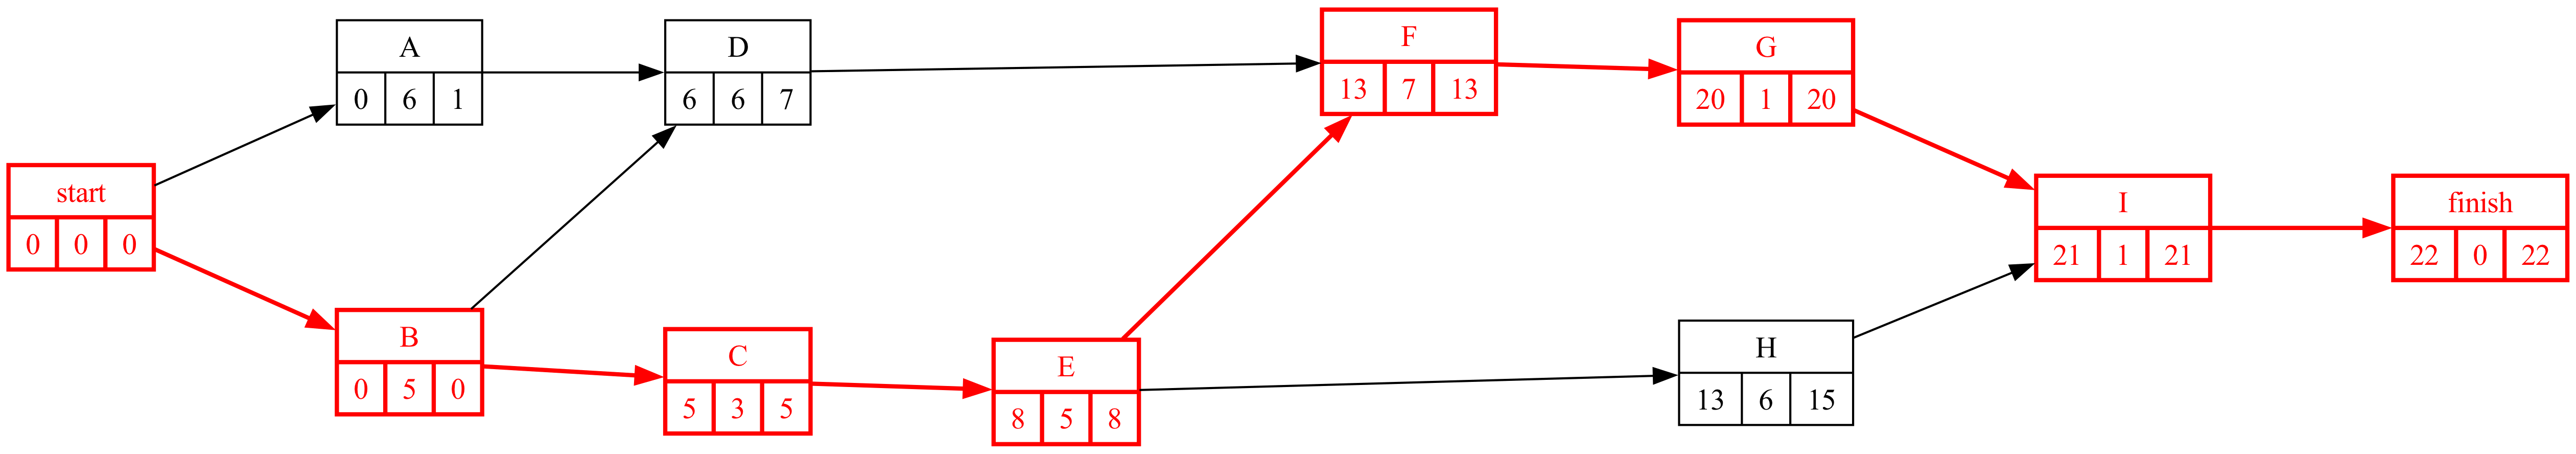

In [9]:
#| fig-cap: "Grafo Roy de la planificación"
#| label: fig-pert
proyecto.display_roy_pasos(datos_proyecto['duration'])

## Apartado 1

In [10]:
display(Markdown(pregunta_1))

1. (A) Calcule, actividad a actividad y en total, las emisiones planificadas a la fecha (PE), las emisiones «ganadas» (EE = plan × avance físico) y las reales (AE), el índice de desempeño de emisiones EPI = EE / AE y la previsión de emisiones al cierre EAC = presupuesto / EPI. ¿Se cumple el indicador del acta?  

In [11]:
#| tbl-cap: "PE, EE y AE actividad a actividad (t CO₂)"
#| label: tbl-detalle
detalle[['plan (t)', 'planificado hasta la semana', 'PE = plan·fracción', 'avance (%)', 'EE = plan·avance', 'AE']]

,plan (t),planificado hasta la semana,PE = plan·fracción,avance (%),EE = plan·avance,AE
A,30.0,6 de 6,30·1.00 = 30.0,100,30·1.00 = 30.0,42.0
B,30.0,5 de 5,30·1.00 = 30.0,100,30·1.00 = 30.0,36.0
C,70.0,3 de 3,70·1.00 = 70.0,100,70·1.00 = 70.0,84.0
D,80.0,5 de 6,80·0.83 = 66.7,33,80·0.33 = 26.4,31.7
E,50.0,3 de 5,50·0.60 = 30.0,30,50·0.30 = 15.0,19.5
F,20.0,0 de 7,20·0.00 = 0.0,0,20·0.00 = 0.0,0.0
G,80.0,0 de 1,80·0.00 = 0.0,0,80·0.00 = 0.0,0.0
H,40.0,0 de 6,40·0.00 = 0.0,0,40·0.00 = 0.0,0.0
I,70.0,0 de 1,70·0.00 = 0.0,0,70·0.00 = 0.0,0.0


In [12]:
indicadores = pd.Series({'PE (t)': PE, 'EE (t)': EE, 'AE (t)': AE, 'EE − AE (t)': EE - AE, 'EE − PE (t)': EE - PE,
                         'EPI = EE / AE': EPI, 'índice de avance EE / PE': EE / PE,
                         'EAC = presupuesto / EPI (t)': EAC, 'exceso previsto sobre el presupuesto (t)': EAC - presupuesto_emisiones})
display(indicadores.round(2).to_frame('valor').T)
Markdown(f'''EPI = {EE:.1f} / {AE:.1f} = **{EPI:.2f}**: por cada tonelada planificada para el trabajo hecho se han emitido {1 / EPI:.2f}. Previsión al cierre **{EAC:.0f} t** frente a las {presupuesto_emisiones:.0f} del acta: el indicador **no se cumple** si no cambia el ritmo de emisión.''')

,PE (t),EE (t),AE (t),EE − AE (t),EE − PE (t),EPI = EE / AE,índice de avance EE / PE,EAC = presupuesto / EPI (t),exceso previsto sobre el presupuesto (t)
valor,226.67,171.4,213.2,-41.8,-55.27,0.8,0.76,584.62,114.62


EPI = 171.4 / 213.2 = **0.80**: por cada tonelada planificada para el trabajo hecho se han emitido 1.24. Previsión al cierre **585 t** frente a las 470 del acta: el indicador **no se cumple** si no cambia el ritmo de emisión.

## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. (A) Explique por qué las emisiones reales están por debajo de las previstas a la fecha y, a la vez, el proyecto va camino de superar el presupuesto de emisiones. ¿Qué dos efectos se mezclan en el acumulado?  

Se mezclan dos efectos de signo contrario. El proyecto va **retrasado** (EE/PE = 0.76: se ha hecho menos trabajo del previsto a la fecha), y por eso ha emitido menos que lo planificado a la fecha: 213 t frente a 227. Pero por el trabajo que sí se ha hecho ha emitido **más de lo previsto** (EPI = 0.80): las actividades empezadas (D, E, y las terminadas) emiten entre un 20 y un 40 % más por unidad de avance que el plan. El acumulado compara dos cosas que no son comparables (lo emitido por el trabajo hecho con lo previsto para un trabajo mayor); EE es la referencia correcta, exactamente como en el valor ganado de costes (lección 14): AE < PV no dice nada de la eficiencia; EV − AC sí.

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. (B) Según los criterios de referencia, ¿cumple el borrador del informe? ¿Qué cifras tendría que contener? Clasifique cada fuente de emisión del enunciado en su alcance.  

**S5.** El indicador está en el acta de constitución: se informa como el coste, con PE, EE, AE, el índice y la previsión al cierre. El borrador da un dato cierto (213 < 227) que lleva a la conclusión contraria a la correcta (EAC 585 t > 470): es una verdad a medias (C2) o, si el jefe de proyecto conoce el EPI, información fuera de contexto (C3). Las cifras que debe contener: EPI 0.80, EAC 585 t, retraso EE/PE 0.76, causas y medidas. **S6.** Clasificación de las fuentes: gasóleo de la maquinaria propia: alcance 1; grupo electrógeno de la obra: alcance 1; electricidad comprada a la red: alcance 2; transporte de materiales por un transportista contratado: alcance 3; vehículos de la subcontrata de montaje: alcance 3. La regla es quién controla la fuente: el combustible de lo propio es alcance 1 aunque lo queme un camión; el mismo camión de un transportista contratado es alcance 3; la electricidad comprada es siempre alcance 2.

In [15]:
preguntas_test = [
    ('Si las emisiones reales acumuladas están por debajo de las planificadas a la fecha pero EPI < 1, el proyecto…', ['va retrasado y emite más de lo previsto por unidad de trabajo', 'cumple el indicador', 'va adelantado', 'emite menos de lo previsto por unidad de trabajo'],
     'AE < PE por el retraso; EE < AE por la ineficiencia.'),
    ('Las emisiones de «transporte de materiales por un transportista contratado» son…', ['alcance 3', 'alcance 1', 'alcance 2', 'no se contabilizan'],
     'S6: fuente de la cadena de valor no controlada por la organización.'),
    ('Las emisiones de «gasóleo de la maquinaria propia» son…', ['alcance 1', 'alcance 2', 'alcance 3', 'no se contabilizan'],
     'S6: combustión en una fuente propia o controlada.'),
    ('La previsión de emisiones al cierre con el método del valor ganado es…', ['presupuesto de emisiones / EPI', 'emisiones reales acumuladas × 2', 'PE + AE', 'presupuesto − AE'],
     'Mismo razonamiento que EAC = BAC / CPI.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — huella del proyecto')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
from pmule import muestra_test
muestra_test(preguntas_test)

$CATEGORY: Sostenibilidad 20 — huella del proyecto

::Sostenibilidad 20 — huella del proyecto P1::Si las emisiones reales acumuladas están por debajo de las planificadas a la fecha pero EPI < 1, el proyecto… {=va retrasado y emite más de lo previsto por unidad de trabajo ~cumple el indicador ~va adelantado ~emite menos de lo previsto por unidad de trabajo ####AE < PE por el retraso; EE < AE por la ineficiencia.}

::Sostenibilidad 20 — huella del proyecto P2::Las emisiones de «transporte de materiales por un transportista contratado» son… {~no se contabilizan =alcance 3 ~alcance 2 ~alcance 1 ####S6: fuente de la cadena de valor no controlada por la organización.}

::Sostenibilidad 20 — huella del proyecto P3::Las emisiones de «gasóleo de la maquinaria propia» son… {~no se contabilizan =alcance 1 ~alcance 2 ~alcance 3 ####S6: combustión en una fuente propia o controlada.}

::Sostenibilidad 20 — huella del proyecto P4::La previsión de emisiones al cierre con el método del valor ganado es…

## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. (C) Redacte el párrafo del informe al patrocinador y lo que dice al jefe de proyecto. Aplique la rúbrica.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Párrafo para el patrocinador (modelo): «A la semana 11 el proyecto lleva emitidas 213 t por un trabajo que el plan valoraba en 171 t (EPI 0.80); el avance es del 36% frente al 48% previsto. Si no cambia el ritmo, el cierre se prevé en 585 t, 115 por encima del indicador del acta. Causas identificadas y medidas: …». Al jefe de proyecto: el acumulado sin referencia es el mismo error que informar AC sin EV; si el patrocinador rehace la cuenta en el cierre, el problema no serán las toneladas sino el informe. Prueba de publicidad: ¿firmaría el informe si llevara anexa la tabla del apartado 1?